In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from lib import neurons, input_gen, driver, utils

In [2]:
b = 2.75
bk = 4.75
beta = 0
n = 3
nd = 300
ns_avg = 200
ns_min = 100
ns_max = 300
rng = jax.random.PRNGKey(42)
subkey, rng = jax.random.split(rng)
ns_array = jax.random.randint(subkey, (nd,), minval=ns_min, maxval=ns_max+1)
l_array = jnp.sqrt(ns_array)

xs_gen = input_gen.Normal_VariableNs(nd, ns_max)
ns_mask = xs_gen.get_mask(ns_array)
hyper = neurons.HyperConfig2(nd=nd, ns=ns_avg, ns_max=ns_max, n=n, b=b, bk=bk, beta=beta, l_array=l_array, ns_mask=ns_mask)
hyperD = neurons.HyperDynConfig2(b=jnp.array([b, b-0.15]), bk=jnp.array([bk, bk]), beta=jnp.array([beta, beta]), l_array=jnp.array([l_array, l_array]), ns_mask=jnp.array([ns_mask, ns_mask]))
neuron = neurons.Neuron_Decay_Int_VariableNs(hyper)


In [3]:
my_driver = driver.Driver2_parallel_states(
    neuron=neuron,
    xs_generator=xs_gen,
    rng=jax.random.PRNGKey(111111),
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000,
    n_tested_patterns=1000,
    )

In [14]:
my_driver.run(
    n_init_steps=8000,
    n_steps_phase1=30000,
    n_steps_phase2=20000,
    n_steps_phase3=10000,
    test_every_phase3=50,
    bs=None),


(None,)

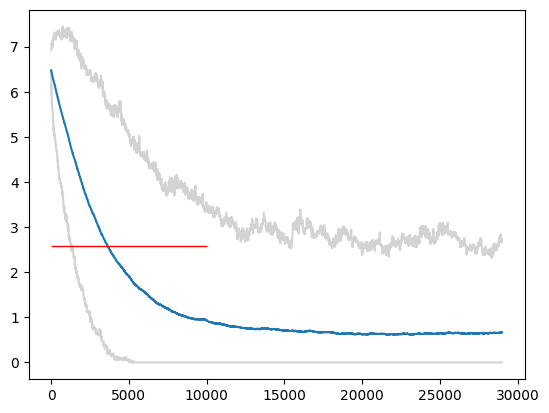

In [15]:
idx = 1
mean = np.mean(my_driver.transient_record[:, idx, :], axis=-1)
lower = np.percentile(my_driver.transient_record[:, idx, :], 1, axis=-1)
upper = np.percentile(my_driver.transient_record[:, idx, :], 99, axis=-1)

steady_upper = np.percentile(my_driver.steady_record[:, idx, :], 99, axis=-1)
steady_upper = np.mean(steady_upper, axis=0)

plt.plot(upper, color='lightgrey')
plt.plot(lower, color='lightgrey')
plt.plot(mean)
plt.hlines(steady_upper, 0, 10000, colors='red', linestyles='-', linewidth=1)

(array([33., 32., 26., 24., 36., 25., 31., 21., 29., 43.]),
 array([100.        , 120.        , 140.        , 159.99998474,
        179.99998474, 199.99998474, 219.99996948, 239.99996948,
        259.99996948, 279.99996948, 299.99996948]),
 <BarContainer object of 10 artists>)

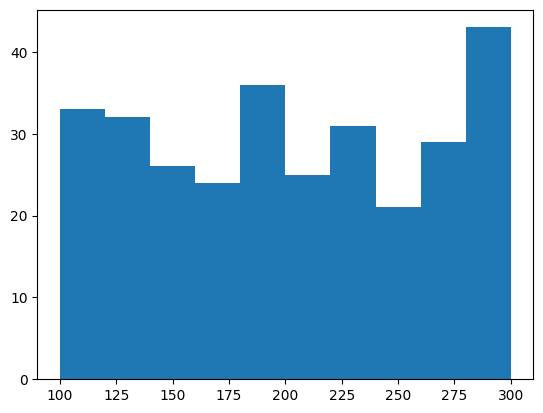

In [16]:
plt.hist(l_array**2)

In [21]:
jnp.repeat(jnp.arange(3)[None, :], 4, axis=0)

Array([[0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2]], dtype=int32)

In [3]:
n_steps = 1000
re_sample_every = 100
ws_record = jnp.zeros((n_steps, nd))
xs = xs_gen.generate(rng, n_patterns=re_sample_every, mask=ns_mask)

subkey, rng = jax.random.split(rng)
state = neuron.init_state(subkey, hyperD)

In [4]:
for t in range(n_steps):
    if t % re_sample_every == 0 and t > 0:
        subkey, rng = jax.random.split(rng)
        xs = xs_gen.generate(subkey, n_patterns=re_sample_every, mask=ns_mask)
        print(f"Resampled inputs at time step {t}", end='\r')
    state = neuron.update(hyperD, state, xs[t % re_sample_every])
    tmp_w = state.w 
    ws = jnp.linalg.norm(tmp_w, axis=1)
    ws_record = ws_record.at[t].set(ws)
    

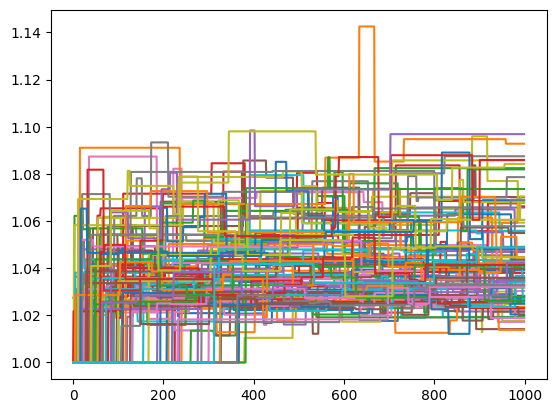

In [5]:
for i in range(100):
    plt.plot(ws_record[:, i] / l_array[i] * jnp.sqrt(ns_avg))

In [6]:
ws_record[-1, 3]

Array(0.8673526, dtype=float32)

In [7]:
ns_array[3]

Array(135, dtype=int32)

In [3]:
key = jax.random.PRNGKey(0)

print(jax.random.randint(key, (10,), minval=0, maxval=300))
print(jax.random.randint(key, (10,), minval=0, maxval=100))

[289   0 212  73  71 147 132  23 213   3]
[89  0 12 73 71 47 32 23 13  3]
